In [1]:
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

pd.set_option("display.max_rows", 999)
pd.set_option("display.max_columns", 999)

CUSTOM_COLOR = "#002E3F"

from config import DATA_VERSION_IDENTIFIER, SAVE_FILES

### Utility functions

In [2]:
def select_samples(df, source="BM"):
    n1 = len(df)
    df = df[
        (df.source == source) &
        df.year.notna() &
        # Discard megakaryocyte (executor does not handle this at this point) 
        ~df.year.str.contains('megat', na=False) & 
        # Select samples with over 10% BM blasts OR PML-RARA is positive
        ((df.bm_blast > 10) | (df["PML-RARA"] == "POS")) &
        # Select samples where time from diagnosis to BM aspiration <= 30 days
        (df.time_diff_dg_mgg <= 30)
    ]
    n2 = len(df)
    num_patients = len(df.henkilotunnus.value_counts())
    print(f"- Found {n2}/{n1} samples from {num_patients} patients")
    # get only one slide for each patient
    df = df.drop_duplicates(subset=["henkilotunnus"], keep="first")
    print("- Kept one sample per patient.")
    print(f"- Number of samples: {len(df)}")
    return df


COLUMNS_TO_MAP = [ 
    'FLT3_mutations',
    'IDH_mutations',
    'JAK_mutations',
    'CpG_mutations',
    'Transcription_mutations',
    'Spliceosome_mutations',
    'MDS_related_mutations',
    'chromatin_cohesin_mutations',
    'RTK_RAS_mutations',
    'NPM1_FLT3',
    'BCOR_mutations',
    'GATA_mutations',
    'RAS_mutations',
    'complex_karyotype',
    'monosomal_karyotype',
    "translocation3",
    "translocation11",
]

def replace_integer_mutation_labels_with_string(df, mapping, columns=None, dtype_filter=None, inplace=False):
    """
    Map values in specified columns of a DataFrame using a dictionary.
    
    Parameters:
        df (pd.DataFrame): The input DataFrame.
        mapping (dict): Dictionary with value mappings (e.g., {0: "NEG", 1: "POS"}).
        columns (list, optional): List of column names to apply the mapping to. 
                                  If None, all columns are considered.
        dtype_filter (str or type, optional): Only apply mapping to columns of this dtype.
                                              Examples: 'int64', 'object', np.integer, etc.
        inplace (bool): Whether to modify the DataFrame in place. Default is False.
    
    Returns:
        pd.DataFrame: The DataFrame with mapped values (if inplace=False).
    """
    if not inplace:
        df = df.copy()

    if columns is None:
        columns = df.columns

    for col in columns:
        if col in df.columns:
            if dtype_filter is None or df[col].dtype == dtype_filter or pd.api.types.is_dtype_equal(df[col].dtype, dtype_filter):
                df[col] = df[col].replace(mapping)
    
    return df

def summarize_label_ratio(df):
    summary = []
    for col in df.columns:
        col_values = df[col]
        pos_count = (col_values == 'POS').sum()
        neg_count = (col_values == 'NEG').sum()
        nan_count = col_values.isna().sum()

        total_valid = pos_count + neg_count
        if total_valid > 0:
            pos_ratio = pos_count / total_valid
            neg_ratio = neg_count / total_valid
            nan_ratio = nan_count / (total_valid + nan_count)
            summary.append({
                'variable': col,
                'N': total_valid,
                'POS': pos_count,
                'NEG': neg_count,
                'NaN': nan_count,
                'POS_ratio': round(pos_ratio, 3),
                'NEG_ratio': round(neg_ratio, 3),
                'NaN_ratio': round(nan_ratio, 3),
            })
    summary = pd.DataFrame(summary)
    
    return summary

def visualize_mutation_occurrence(df, figsize=(10, 11), fontsize=10, title="Mutation occurrence", save_path=None):

    df = df.sort_values(by='POS', ascending=True)
    
    fig, ax = plt.subplots(figsize=figsize) 
    
    # Plot as horizontal stacked bar chart
    df.set_index("variable")[['POS', 'NEG', 'NaN']].plot(
        kind='barh',
        stacked=True,
        color=['skyblue', 'tab:red', 'grey'],
        ax=ax,
    )
    # Add POS percentage annotation inside the blue bar
    for i, (index, row) in enumerate(df.iterrows()):
        pos_count = row['POS']
        pos_percent = row['POS_ratio'] * 100
        
        if pos_count > 0:
            # Position text roughly in the center of the blue bar
            xpos = pos_count / 2  
            ax.text(xpos, i, f'{pos_percent:.0f}%', va='center', ha='center', color='black', fontsize=fontsize-3)
    
    # Remove plot edges (spines)
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_visible(False)
    
    ax.legend(
        loc='upper left',
        bbox_to_anchor=(1, 0.99),
        fontsize=fontsize-2,
    )
    
    plt.xlabel("Count", fontsize=fontsize-2)
    plt.ylabel("")
    plt.xticks(fontsize=fontsize-2)
    plt.yticks(fontsize=fontsize-2)

    plt.title(title, fontsize=fontsize)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()


## Version history
- `10.11.2025`: Notebook created and first label dataset exported.
- `19.11.2025`: Add PML-RARA in the study cohort. New label dataset created.
- `10.12.2025`: Some chromosome aberration variables had mistakes that Oscar fixed -> New  labelset export
- `21.01.2026`: Several changes for criterias to select samples
    - BM blast (%) threshold from 6 to 10
    - Minimum time from diagnosis to Bone marrow aspiration 30 days
- `7.4.2026`: Kept 10% BM blast threshold, but additionally select all PML-RARA positive samples.


## Data paths

In [3]:
from core.dummy import save_with_dummy

SOURCE_DATA_DIR = "~/mounts/research/husdatalake/disease/scripts/AML_mutation_prediction/clinical_input_data"
AML_ALL_SAMPLES_PATH = f"{SOURCE_DATA_DIR}/input_data_AML_all_samples.xlsx"
AML_DG_SAMPLES_PATH  = f"{SOURCE_DATA_DIR}/input_data_AML_dg_samples.xlsx"
AML_VAF_DATA_PATH    = f"{SOURCE_DATA_DIR}/input_data_AML_all_samples_VAF.xlsx"

## Selection of the study cohort and dataset generation

We will select the samples and mutation/cytogenetic target variables using the following rules:
1) Select **diagnostic** samples
2) Blasts > 10% (Makes sure that truly diagnostic samples are selected) or PML-RARA == True (Maximize positive PML-RARA samples)
3) Time from DG to BMA <= 30 days
4) Prevalence of mutated samples >= 3%
5) Prevalence of mutated samples >= 10
6) Select both **de novo** and **secondary** AML samples
7) Export study cohort, with mutation/cytogenetic aberration labels
8) Get survival data
9) Get VAF data

#### Select samples (Parts 1-3)

We select samples from patiens who have both BM and PB samples.

In [4]:
aml_dg = pd.read_excel(AML_DG_SAMPLES_PATH)

# Drop Mega and PB related samples, select samples with > 10% blasts and time from DG to BMA <= 30 days
print("BONE MARROW:")
aml_dg_bm = select_samples(aml_dg, source="BM")

# Select samples with > 10% blasts and time from DG to BMA <= 30 days
print("\nPERIPHERAL BLOOD:")
aml_dg_pb = select_samples(aml_dg, source="PB")

# Find patients with both BM and PB
df = pd.merge(aml_dg_bm, aml_dg_pb, on="henkilotunnus", how="inner")
patients = df.henkilotunnus
print("\nBONE MARROW + PERIPHERAL BLOOD:")
print(f"- Found {len(patients)} patients with both BM and PB samples")

aml_dg_bm = aml_dg_bm[aml_dg_bm.henkilotunnus.isin(patients)]
aml_dg_pb = aml_dg_pb[aml_dg_pb.henkilotunnus.isin(patients)]

assert aml_dg_bm.shape[0] == aml_dg_pb.shape[0]

if SAVE_FILES:
    # save "raw" clinical data for ELN risk analysis (we need all variables as they are for ELN class generation)
    V = DATA_VERSION_IDENTIFIER
    save_with_dummy(aml_dg_bm, f"data/{V}/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_bm_{V}.csv", id_columns=["album_id", "henkilotunnus"])
    save_with_dummy(aml_dg_pb, f"data/{V}/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_pb_{V}.csv", id_columns=["album_id", "henkilotunnus"])


# tranform some of the column values from int labels (0, 1) to string (NEG, POS) to have uniform format
aml_dg_bm = replace_integer_mutation_labels_with_string(aml_dg_bm, mapping={0: "NEG", 1: "POS"}, columns=COLUMNS_TO_MAP)
aml_dg_pb = replace_integer_mutation_labels_with_string(aml_dg_pb, mapping={0: "NEG", 1: "POS"}, columns=COLUMNS_TO_MAP)

BONE MARROW:
- Found 628/1799 samples from 625 patients
- Kept one sample per patient.
- Number of samples: 625

PERIPHERAL BLOOD:
- Found 603/1799 samples from 603 patients
- Kept one sample per patient.
- Number of samples: 603

BONE MARROW + PERIPHERAL BLOOD:
- Found 582 patients with both BM and PB samples
Saved: data/03-06-2026/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_bm_03-06-2026.csv
Saved: data/03-06-2026/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_bm_03-06-2026_DUMMY.csv
Saved: data/03-06-2026/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_pb_03-06-2026.csv
Saved: data/03-06-2026/unprocessed_clinical/aml_mut_pred_unprocessed_clinical_data_pb_03-06-2026_DUMMY.csv


#### Select target labels (Parts 4-6)

In [5]:
# extract all available target variables
# NOTE: We can do this using either BM or PB data, it does not matter
df_mut = aml_dg_bm.loc[:, aml_dg_bm.apply(lambda col: set(col.dropna()).issubset({'POS', 'NEG'}))]
# NOTE: We drop "t_3" and "t_11", because the table has variables: "translocation3" and "translocation11" which has more positives 
mutation_variables = df_mut.drop(columns=["no_chrm_alteration", "no_mutation", "t_11", "t_3"]).columns.to_list()

In [6]:
df = aml_dg_bm.copy()

# select target variables only
df = df[mutation_variables]

# calculate summary label counts
summary = summarize_label_ratio(df)

# Keep mutations with >= 3% and > 10 POS labels and > 0 negatives
summary = summary[(summary.POS_ratio >= 0.03) & (summary.POS >= 10) & (summary.NEG > 0)] # & (summary.POS >= 10)

summary = summary.sort_values(by='POS', ascending=False)
mutation_variables_after_filtering = summary.variable.to_list()
print(f"Number of mutation/cytogenetic related variables: {len(summary)}\n")
display(summary)

Number of mutation/cytogenetic related variables: 65



,variable,N,POS,NEG,NaN,POS_ratio,NEG_ratio,NaN_ratio
337,RTK_RAS_mutations,401,258,143,181,0.643,0.357,0.311
332,CpG_mutations,385,193,192,197,0.501,0.499,0.338
329,FLT3_mutations,488,181,307,94,0.371,0.629,0.162
243,FLT3_ITD,488,161,327,94,0.330,0.670,0.162
278,NPM1,472,125,347,110,0.265,0.735,0.189
335,MDS_related_mutations,337,120,217,245,0.356,0.644,0.421
333,Transcription_mutations,382,104,278,200,0.272,0.728,0.344
234,DNMT3A,383,99,284,199,0.258,0.742,0.342
336,chromatin_cohesin_mutations,335,93,242,247,0.278,0.722,0.424
330,IDH_mutations,383,86,297,199,0.225,0.775,0.342


In [7]:
string = "t_"
summary_subset = summary[summary.variable.str.contains(string)]
summary_subset

,variable,N,POS,NEG,NaN,POS_ratio,NEG_ratio,NaN_ratio
197,t_8,582,27,555,0,0.046,0.954,0.00
202,t_8_21,559,25,534,23,0.045,0.955,0.04
149,t_15,582,23,559,0,0.040,0.960,0.00
150,t_15_17,559,23,536,23,0.041,0.959,0.04


#### Extra: Merge similar variables and delete redundant ones

There are some variables in the selected dataset whose function is similar/close to each other. Next we will handle those:

In [8]:
# create new table for clarity
#aml_dg_bm_new = aml_dg_bm.copy()
#aml_dg_pb_new = aml_dg_pb.copy()

def fuse_columns_or(row):
    if row.isna().all():
        return np.nan
    elif (row == 'POS').any():
        return 'POS'
    else:
        return 'NEG'

def fuse_columns_and(row):
    if row.isna().all():
        return np.nan
    elif (row == 'POS').all():
        return 'POS'
    else:
        return 'NEG'

# create new variables
# Bone marrow:
aml_dg_bm["RUNX1-RUNX1T1_OR_t_8_21"] = aml_dg_bm[["RUNX1-RUNX1T1", "t_8_21"]].apply(fuse_columns_or, axis=1)
aml_dg_bm["TP53_OR_monosomy17_del_17p"] = aml_dg_bm[["TP53", "monosomy17_del_17p"]].apply(fuse_columns_or, axis=1)
aml_dg_bm["NPM1_AND_FLT3_ITD"] = aml_dg_bm[["NPM1", "FLT3_ITD"]].apply(fuse_columns_and, axis=1)

# Peripheral blood:
aml_dg_pb["RUNX1-RUNX1T1_OR_t_8_21"] = aml_dg_pb[["RUNX1-RUNX1T1", "t_8_21"]].apply(fuse_columns_or, axis=1)
aml_dg_pb["TP53_OR_monosomy17_del_17p"] = aml_dg_pb[["TP53", "monosomy17_del_17p"]].apply(fuse_columns_or, axis=1)
aml_dg_pb["NPM1_AND_FLT3_ITD"] = aml_dg_pb[["NPM1", "FLT3_ITD"]].apply(fuse_columns_and, axis=1)


Exclude redundant variables.

In [9]:
# define variables to be excluded
EXCLUDED_VARIABLES = [
    # NOTE: Monosomy 5 (selected: "monosomy_del_5q")
    "monosomy5",
    "monosomy_del_5",
    "del_5q",
    
    # NOTE: monosomy 17 (selected: "monosomy17_del_17p")
    "monosomy17",

    # NOTE: monosomy 7 (selected: "monosomy_del_7")
    "monosomy7_del_7q",
    "monosomy7",
    "del_7q",
    
    # NOTE: trisomy 8 (selected: "trisomy_add_dup_amp_8")
    "trisomy8",

    # NOTE: trisomy 21 (selected: "trisomy_add_dup_amp_21")
    "trisomy_add_dup_amp_21",
    "trisomy21",
    
    # NOTE: RUNX1-RUNX1T1 related (new fusion variable: "RUNX1-RUNX1T1_OR_t_8_21") replaces these
    "RUNX1-RUNX1T1",
    "t_8_21",
    
    # NOTE: Exclude "t_8"
    "t_8",
    
    # NOTE: JAK (selected: "JAK2" because it has less NaNs)
    "JAK_mutations",

    # NOTE: 
    "t_15_17", 
    "t_15",
]

# New fusion variables to include
NEW_FUSION_VARIABLES = ["RUNX1-RUNX1T1_OR_t_8_21", "TP53_OR_monosomy17_del_17p", "NPM1_AND_FLT3_ITD"]

# Some variables that must be included
EXTRA_VARIABLES = [] # NOTE (7.4.2026): new version has enough positives for PML-RARA so this is not needed

# delete excluded variables and add new fusion variables
final_mutation_variables = [item for item in mutation_variables_after_filtering if item not in EXCLUDED_VARIABLES] + NEW_FUSION_VARIABLES + EXTRA_VARIABLES


### Bone marrow

In [10]:
# summarize mutation labels:
df = aml_dg_bm.copy()
df = df[final_mutation_variables]
summary = summarize_label_ratio(df)
summary = summary.sort_values(by='POS', ascending=False)
# get final mutation variables in nice order
final_mutation_variables = summary.variable.to_list()

print(f"Number of mutation/cytogenetic related variables: {len(summary)}\n")
#visualize_mutation_occurrence(summary, figsize=(12, 9), fontsize=11, title="Mutation occurrence (All AML samples)", save_path=None)
#display(summary[summary.variable.isin(["RUNX1-RUNX1T1_OR_t_8_21", "PML-RARA", "CBFB-MYH11", "monosomy5_del_5q"])])
display(summary)

Number of mutation/cytogenetic related variables: 52



,variable,N,POS,NEG,NaN,POS_ratio,NEG_ratio,NaN_ratio
0,RTK_RAS_mutations,401,258,143,181,0.643,0.357,0.311
1,CpG_mutations,385,193,192,197,0.501,0.499,0.338
2,FLT3_mutations,488,181,307,94,0.371,0.629,0.162
3,FLT3_ITD,488,161,327,94,0.330,0.670,0.162
4,NPM1,472,125,347,110,0.265,0.735,0.189
5,MDS_related_mutations,337,120,217,245,0.356,0.644,0.421
6,Transcription_mutations,382,104,278,200,0.272,0.728,0.344
7,DNMT3A,383,99,284,199,0.258,0.742,0.342
8,chromatin_cohesin_mutations,335,93,242,247,0.278,0.722,0.424
9,IDH_mutations,383,86,297,199,0.225,0.775,0.342


### Peripheral blood

In [11]:
# summarize mutation labels:
df = aml_dg_pb.copy()
df = df[final_mutation_variables]
summary = summarize_label_ratio(df)
summary = summary.sort_values(by='POS', ascending=False)
# get final mutation variables in nice order
final_mutation_variables = summary.variable.to_list()

print(f"Number of mutation/cytogenetic related variables: {len(summary)}\n")
#visualize_mutation_occurrence(summary, figsize=(12, 9), fontsize=11, title="Mutation occurrence (All AML samples)", save_path=None)
display(summary)

Number of mutation/cytogenetic related variables: 52



,variable,N,POS,NEG,NaN,POS_ratio,NEG_ratio,NaN_ratio
0,RTK_RAS_mutations,401,258,143,181,0.643,0.357,0.311
1,CpG_mutations,385,193,192,197,0.501,0.499,0.338
2,FLT3_mutations,488,181,307,94,0.371,0.629,0.162
3,FLT3_ITD,488,161,327,94,0.330,0.670,0.162
4,NPM1,472,125,347,110,0.265,0.735,0.189
5,MDS_related_mutations,337,120,217,245,0.356,0.644,0.421
6,Transcription_mutations,382,104,278,200,0.272,0.728,0.344
7,DNMT3A,383,99,284,199,0.258,0.742,0.342
8,chromatin_cohesin_mutations,335,93,242,247,0.278,0.722,0.424
9,IDH_mutations,383,86,297,199,0.225,0.775,0.342


#### 6) Export study cohort, with mutation/cytogenetic aberration labels

- Timepoint: **Diagnosis**
- Etiology: **De Novo** and **secondary** AML
- Labels: **All**

In [12]:

def get_label_table(df, final_mutation_variables):


    subject_id = [i for i in range(len(df))]
    df["subject_id"] = subject_id

    # select album_id, year and target variables
    df = df[["subject_id", "album_id", "year"] + final_mutation_variables]

    # force album_id to string
    #df.loc[:, "album_id"] = df["album_id"].astype(int).astype(str)
    df["album_id"] = df["album_id"].astype(str)

    # rename year to database_id
    #df = df.rename(columns={"year": "database_id"})

    # convert string values (POS/NEG) to integer (1/0)
    df[final_mutation_variables] = df[final_mutation_variables].replace({'POS': 1, 'NEG': 0})


    return df


def rename_to_excel_style_columns(df, cols_to_rename):
    """
    Renames specified columns in a DataFrame to Excel-style names (A, B, ..., Z, AA, AB, ...).

    Parameters:
        df (pd.DataFrame): The DataFrame whose columns will be renamed.
        cols_to_rename (list): List of column names to rename.

    Returns:
        pd.DataFrame: A new DataFrame with selected columns renamed.
    """

    def number_to_excel_col(n):
        """Convert a 1-based index to an Excel-style column label."""
        name = ""
        while n > 0:
            n, remainder = divmod(n - 1, 26)
            name = chr(65 + remainder) + name
        return name

    # Get number of columns to rename
    num = len(cols_to_rename)
    new_names = [number_to_excel_col(i + 1) for i in range(num)]

    # Create rename mapping
    rename_map = dict(zip(cols_to_rename, new_names))

    # Return new DataFrame with renamed columns
    return df.rename(columns=rename_map), rename_map

#### **NB:** Override selected labels with labels from `24.02-2026`-dataset
- Compared to that dataset, only PML-RARA positive samples have been included more
- Overall label distribution have shanged a bit but this does not affect final label selection.
- To minimize manual rework, simply use old label map

In [13]:
mutation_map = {
    "RTK_RAS_mutations": "A",
    "NPM1_AND_FLT3_ITD": "B",
    "CpG_mutations": "C",
    "FLT3_mutations": "D",
    "FLT3_ITD": "E",
    "NPM1": "F",
    "MDS_related_mutations": "G",
    "Transcription_mutations": "H",
    "DNMT3A": "I",
    "chromatin_cohesin_mutations": "J",
    "IDH_mutations": "K",
    "complex_karyotype": "L",
    "TET2": "M",
    "Spliceosome_mutations": "N",
    "monosomal_karyotype": "O",
    "RAS_mutations": "P",
    "IDH2": "Q",
    "trisomy_add_dup_amp_8": "R",
    "monosomy_del_7": "S",
    "TP53_OR_monosomy17_del_17p": "T",
    "monosomy5_del_5q": "U",
    "RUNX1": "V",
    "NRAS": "W",
    "SRSF2": "X",
    "TP53": "Y",
    "BCOR_mutations": "Z",
    "FLT3_TKD": "AA",
    "BCOR": "AB",
    "ASXL1": "AC",
    "RUNX1-RUNX1T1_OR_t_8_21": "AD",
    "monosomy17_del_17p": "AE",
    "WT1": "AF",
    "IDH1": "AG",
    "CEBPA": "AH",
    "PTPN11": "AI",
    "translocation11": "AJ",
    "KRAS": "AK",
    "JAK2": "AL",
    "GATA_mutations": "AM",
    "STAG2": "AN",
    "translocation3": "AO",
    "GATA2": "AP",
    "NF1": "AQ",
    "CBL": "AR",
    "PHF6": "AS",
    "U2AF1": "AT",
    "KIT": "AU",
    "KMT2A_rearrangement": "AV",
    "CBFB-MYH11": "AW",
    "EP300": "AX",
    "EZH2": "AY",
    "PML-RARA": "AZ"
}

final_mutation_variables = list(mutation_map.keys())


In [14]:
import json

# create label tables
V = DATA_VERSION_IDENTIFIER

# BM
df_export_bm = get_label_table(aml_dg_bm.copy(), final_mutation_variables)
df_export_bm, label_map_bm = rename_to_excel_style_columns(df_export_bm, final_mutation_variables)
df_export_bm = df_export_bm.rename(columns={"year": "database_id"})
if SAVE_FILES:
    save_with_dummy(df_export_bm, f"data/{V}/mutation_labels/aml_mut_pred_sample_ids_bm_{V}.xlsx", id_columns=["subject_id", "album_id", "database_id"])

# PB
df_export_pb = get_label_table(aml_dg_pb.copy(), final_mutation_variables)
df_export_pb, label_map_pb = rename_to_excel_style_columns(df_export_pb, final_mutation_variables)
df_export_pb = df_export_pb.rename(columns={"year": "database_id"})
if SAVE_FILES:
    save_with_dummy(df_export_pb, f"data/{V}/mutation_labels/aml_mut_pred_sample_ids_pb_{V}.xlsx", id_columns=["subject_id", "album_id", "database_id"])

# make sure that BM and PB label mappings are identical
assert label_map_bm == label_map_pb

label_map_bm

Saved: data/03-06-2026/mutation_labels/aml_mut_pred_sample_ids_bm_03-06-2026.xlsx
Saved: data/03-06-2026/mutation_labels/aml_mut_pred_sample_ids_bm_03-06-2026_DUMMY.xlsx
Saved: data/03-06-2026/mutation_labels/aml_mut_pred_sample_ids_pb_03-06-2026.xlsx
Saved: data/03-06-2026/mutation_labels/aml_mut_pred_sample_ids_pb_03-06-2026_DUMMY.xlsx


{'RTK_RAS_mutations': 'A',
 'NPM1_AND_FLT3_ITD': 'B',
 'CpG_mutations': 'C',
 'FLT3_mutations': 'D',
 'FLT3_ITD': 'E',
 'NPM1': 'F',
 'MDS_related_mutations': 'G',
 'Transcription_mutations': 'H',
 'DNMT3A': 'I',
 'chromatin_cohesin_mutations': 'J',
 'IDH_mutations': 'K',
 'complex_karyotype': 'L',
 'TET2': 'M',
 'Spliceosome_mutations': 'N',
 'monosomal_karyotype': 'O',
 'RAS_mutations': 'P',
 'IDH2': 'Q',
 'trisomy_add_dup_amp_8': 'R',
 'monosomy_del_7': 'S',
 'TP53_OR_monosomy17_del_17p': 'T',
 'monosomy5_del_5q': 'U',
 'RUNX1': 'V',
 'NRAS': 'W',
 'SRSF2': 'X',
 'TP53': 'Y',
 'BCOR_mutations': 'Z',
 'FLT3_TKD': 'AA',
 'BCOR': 'AB',
 'ASXL1': 'AC',
 'RUNX1-RUNX1T1_OR_t_8_21': 'AD',
 'monosomy17_del_17p': 'AE',
 'WT1': 'AF',
 'IDH1': 'AG',
 'CEBPA': 'AH',
 'PTPN11': 'AI',
 'translocation11': 'AJ',
 'KRAS': 'AK',
 'JAK2': 'AL',
 'GATA_mutations': 'AM',
 'STAG2': 'AN',
 'translocation3': 'AO',
 'GATA2': 'AP',
 'NF1': 'AQ',
 'CBL': 'AR',
 'PHF6': 'AS',
 'U2AF1': 'AT',
 'KIT': 'AU',
 'KM

In [15]:
label_map_bm

{'RTK_RAS_mutations': 'A',
 'NPM1_AND_FLT3_ITD': 'B',
 'CpG_mutations': 'C',
 'FLT3_mutations': 'D',
 'FLT3_ITD': 'E',
 'NPM1': 'F',
 'MDS_related_mutations': 'G',
 'Transcription_mutations': 'H',
 'DNMT3A': 'I',
 'chromatin_cohesin_mutations': 'J',
 'IDH_mutations': 'K',
 'complex_karyotype': 'L',
 'TET2': 'M',
 'Spliceosome_mutations': 'N',
 'monosomal_karyotype': 'O',
 'RAS_mutations': 'P',
 'IDH2': 'Q',
 'trisomy_add_dup_amp_8': 'R',
 'monosomy_del_7': 'S',
 'TP53_OR_monosomy17_del_17p': 'T',
 'monosomy5_del_5q': 'U',
 'RUNX1': 'V',
 'NRAS': 'W',
 'SRSF2': 'X',
 'TP53': 'Y',
 'BCOR_mutations': 'Z',
 'FLT3_TKD': 'AA',
 'BCOR': 'AB',
 'ASXL1': 'AC',
 'RUNX1-RUNX1T1_OR_t_8_21': 'AD',
 'monosomy17_del_17p': 'AE',
 'WT1': 'AF',
 'IDH1': 'AG',
 'CEBPA': 'AH',
 'PTPN11': 'AI',
 'translocation11': 'AJ',
 'KRAS': 'AK',
 'JAK2': 'AL',
 'GATA_mutations': 'AM',
 'STAG2': 'AN',
 'translocation3': 'AO',
 'GATA2': 'AP',
 'NF1': 'AQ',
 'CBL': 'AR',
 'PHF6': 'AS',
 'U2AF1': 'AT',
 'KIT': 'AU',
 'KM

In [16]:
def dict_diff(d1, d2):
    only_in_d1 = d1.keys() - d2.keys()
    only_in_d2 = d2.keys() - d1.keys()
    different_values = {k: (d1[k], d2[k]) for k in d1.keys() & d2.keys() if d1[k] != d2[k]}

    print("🔹 Keys only in first dict:", only_in_d1)
    print("🔹 Keys only in second dict:", only_in_d2)
    print("🔹 Keys with different values:")
    for k, (v1, v2) in different_values.items():
        print(f"   {k!r}: {v1!r} != {v2!r}")

In [17]:
mutation_map = {
    "RTK_RAS_mutations": "A",
    "NPM1_AND_FLT3_ITD": "B",
    "CpG_mutations": "C",
    "FLT3_mutations": "D",
    "FLT3_ITD": "E",
    "NPM1": "F",
    "MDS_related_mutations": "G",
    "Transcription_mutations": "H",
    "DNMT3A": "I",
    "chromatin_cohesin_mutations": "J",
    "IDH_mutations": "K",
    "complex_karyotype": "L",
    "TET2": "M",
    "Spliceosome_mutations": "N",
    "monosomal_karyotype": "O",
    "RAS_mutations": "P",
    "IDH2": "Q",
    "trisomy_add_dup_amp_8": "R",
    "monosomy_del_7": "S",
    "TP53_OR_monosomy17_del_17p": "T",
    "monosomy5_del_5q": "U",
    "RUNX1": "V",
    "NRAS": "W",
    "SRSF2": "X",
    "TP53": "Y",
    "BCOR_mutations": "Z",
    "FLT3_TKD": "AA",
    "BCOR": "AB",
    "ASXL1": "AC",
    "RUNX1-RUNX1T1_OR_t_8_21": "AD",
    "monosomy17_del_17p": "AE",
    "WT1": "AF",
    "IDH1": "AG",
    "CEBPA": "AH",
    "PTPN11": "AI",
    "translocation11": "AJ",
    "KRAS": "AK",
    "JAK2": "AL",
    "GATA_mutations": "AM",
    "STAG2": "AN",
    "translocation3": "AO",
    "GATA2": "AP",
    "NF1": "AQ",
    "CBL": "AR",
    "PHF6": "AS",
    "U2AF1": "AT",
    "KIT": "AU",
    "KMT2A_rearrangement": "AV",
    "CBFB-MYH11": "AW",
    "EP300": "AX",
    "EZH2": "AY",
    "PML-RARA": "AZ"
}



In [18]:
dict_diff(label_map_bm, mutation_map)

🔹 Keys only in first dict: set()
🔹 Keys only in second dict: set()
🔹 Keys with different values:


### 8) Survival dataset

In [19]:
df = aml_dg_bm.drop(columns=mutation_variables) # NOTE: we can dot this with BM data and just use "henkilotunnus" to find PB samples

print(f"We will start from {df.shape[0]} samples")

#PATTERNS = "ELN|WHO|ERY|MEG|MGK|APL|karyotype|translocation|Source|source|bm_|transfusion"
#EXCLUDED_COLUMNS = ["sukupuoli_selite", "etiology", "album_id", "year", "no_chrm_alteration", "henkilotunnus", "Comment", "no_mutation", "mutations", "fuus", "samplenumber_mgg", "cellularity", "examinations", "samplenumber", "qpati_samplenumber", "anamnesis", "disease", "statement", "patologia_nayte_id", "extid", "diagnose"]
#df = df.drop(columns=df.columns[df.columns.str.contains(PATTERNS)])
#df = df.drop(columns=EXCLUDED_COLUMNS)

# calculate time of death from diagnosis (we need this later)
time_to_death = df.kuolinaika_pvm - df.dg_date_combined
patient_ids = df[["henkilotunnus"]]
sample_ids = df[["album_id", "year"]]

# get variables needed for getting first-line treatment information
df = df[["referral_outside_of_uusimaa", "referral_outside_of_uusimaa_for_allo", "alloHSCT_first_date", "cycle_start_date", "aza_start_date", "aza_ven_start_date"]]

# create new boolean variables from treatment dates
df["HSCT"] = df.alloHSCT_first_date.notna()
df["cyto"] = df.cycle_start_date.notna()
df["aza"] = df.aza_start_date.notna()
df["aza_ven"] = df.aza_ven_start_date.notna()

# drop treatment dates
df = df.drop(columns=["alloHSCT_first_date", "cycle_start_date", "aza_start_date", "aza_ven_start_date"])

# NOTE: Now we modify treatment information

# If HSCT == True, but not treatment information, set cyto=True
# This is done because HSCT cannot be given without proper treatment, i.e. cytostasis
df.loc[~df["cyto"] & ~df["aza"] & ~df["aza_ven"] & df["HSCT"], "cyto"] = True

# If cyto == True, make sure that "aza" and "aza_ven" are false, because cyto is always the dominant one
df.loc[df["cyto"] & df["aza"], "aza"] = False
df.loc[df["cyto"] & df["aza_ven"], "aza_ven"] = False

# If both "aza" and "aza_ven" == True, but "cyto" == False, set "aza" to False because "aza_ven" is the dominant one
df.loc[df["aza"] & df["aza_ven"] & ~df["cyto"], "aza"] = False

# Similarly, if referral outside uusimaa for allo and no treatments, set cyto=True
df.loc[~df["cyto"] & ~df["aza"] & ~df["aza_ven"] & ~df["HSCT"] & df["referral_outside_of_uusimaa_for_allo"], "cyto"] = True

# convert from boolean to int for simplicity
df = df.astype(int)
df["time_to_death"] = time_to_death

print("\n--------------------------------------------------------------------------------------------------------------\n")

# Get number of patients that had referral outside uusimaa but no referral for allo AND no treatment data.
# These patients might have got treatment before moved to HUS or then not.
# These should be checked!
a = df[(df.referral_outside_of_uusimaa == 1) & (df.referral_outside_of_uusimaa_for_allo == 0)].drop(columns=["referral_outside_of_uusimaa", "referral_outside_of_uusimaa_for_allo", "time_to_death"])
print("Number of patients who had referral outside uusimaa but no referral for allo: ", len(a))

# Patients that are missing treatment information
b = a[(a == 0).all(axis=1)]
print("Number of patients who had referral outside uusimaa but no referral for allo AND no treatment data: ", (a == 0).all(axis=1).sum())

# From patients who are missing treatment information, those who did not die within 2 months from diagnosis
c = df.loc[b.index]

print("\nPatiens who died within two monts after diagnosis and had not treatment information:")
display(c[c.time_to_death < pd.to_timedelta(60, unit="D")])
c = c[(c.time_to_death > pd.to_timedelta(60, unit="D")) | (c.time_to_death.isna())]

print("Num patients, missing treatment ", len(c))

# Remove those patients above (referral outside uusimaa but not for allo and treatment information missing)
df = df.drop(c.index)
print("Num selected patients: ", df.shape[0])

print("\n--------------------------------------------------------------------------------------------------------------\n")

a = df.drop(columns=["referral_outside_of_uusimaa", "referral_outside_of_uusimaa_for_allo", "HSCT", "time_to_death"])
a["palliative"] = ((a.aza == 0) & (a.aza_ven == 0) & (a.cyto == 0)).astype(int)

display(a.value_counts(normalize=False))
print()
display((a.value_counts(normalize=True)).round(3))

# get survival data
df_survival = a.copy()
df_survival = df_survival.astype(bool)
df_survival = df_survival.join(time_to_death.rename("time_dg_to_death"))
df_survival["died"] = ~df_survival["time_dg_to_death"].isna()
df_survival = df_survival.join(sample_ids)
df_survival = df_survival.join(patient_ids)
df_survival.head()

# Rename dataframe to specify that these are BM samples
df_survival_bm = df_survival.rename(columns={"year": "database_id"})
display(df_survival_bm.head())

if SAVE_FILES:
    V = DATA_VERSION_IDENTIFIER
    save_with_dummy(df_survival_bm, f"data/{V}/survival/aml_mut_pred_survival_data_bm_{V}.xlsx", id_columns=["album_id", "database_id", "henkilotunnus"])

We will start from 582 samples

--------------------------------------------------------------------------------------------------------------

Number of patients who had referral outside uusimaa but no referral for allo:  63
Number of patients who had referral outside uusimaa but no referral for allo AND no treatment data:  49

Patiens who died within two monts after diagnosis and had not treatment information:


,referral_outside_of_uusimaa,referral_outside_of_uusimaa_for_allo,HSCT,cyto,aza,aza_ven,time_to_death
170,1,0,0,0,0,0,5 days
346,1,0,0,0,0,0,6 days
438,1,0,0,0,0,0,23 days
584,1,0,0,0,0,0,31 days
1034,1,0,0,0,0,0,18 days
1604,1,0,0,0,0,0,12 days


Num patients, missing treatment  43
Num selected patients:  539

--------------------------------------------------------------------------------------------------------------



cyto  aza  aza_ven  palliative
1     0    0        0             290
0     0    0        1             158
      1    0        0              46
      0    1        0              45
Name: count, dtype: int64

cyto  aza  aza_ven  palliative
1     0    0        0             0.538
0     0    0        1             0.293
      1    0        0             0.085
      0    1        0             0.083
Name: proportion, dtype: float64

,cyto,aza,aza_ven,palliative,time_dg_to_death,died,album_id,database_id,henkilotunnus
2,False,False,True,False,298 days,True,300,VisionDB_2018,02139_00197762
4,False,False,False,True,561 days,True,290,VisionDB_2013,02139_00425479
6,False,False,False,True,12 days,True,306,VisionDB_2016,02139_00569925
8,False,True,False,False,470 days,True,298,VisionDB_2018,02139_00648785
14,True,False,False,False,NaT,False,1777,VisionDB_2021,02139_00818770


Saved: data/03-06-2026/survival/aml_mut_pred_survival_data_bm_03-06-2026.xlsx
Saved: data/03-06-2026/survival/aml_mut_pred_survival_data_bm_03-06-2026_DUMMY.xlsx


In [20]:
pb_sample_ids = aml_dg_pb[["henkilotunnus", "year", "album_id"]]
pb_sample_ids = pb_sample_ids.rename(columns={"year": "database_id"})

df_survival_pb = df_survival_bm.drop(columns=["database_id", "album_id"])
df_survival_pb = pd.merge(df_survival_pb, pb_sample_ids, on="henkilotunnus", how="inner")

if SAVE_FILES:
    V = DATA_VERSION_IDENTIFIER
    save_with_dummy(df_survival_pb, f"data/{V}/survival/aml_mut_pred_survival_data_pb_{V}.xlsx", id_columns=["album_id", "database_id", "henkilotunnus"])

df_survival_pb.shape

Saved: data/03-06-2026/survival/aml_mut_pred_survival_data_pb_03-06-2026.xlsx
Saved: data/03-06-2026/survival/aml_mut_pred_survival_data_pb_03-06-2026_DUMMY.xlsx


(539, 9)

3572 days 00:00:00


(0.0, 48.0)

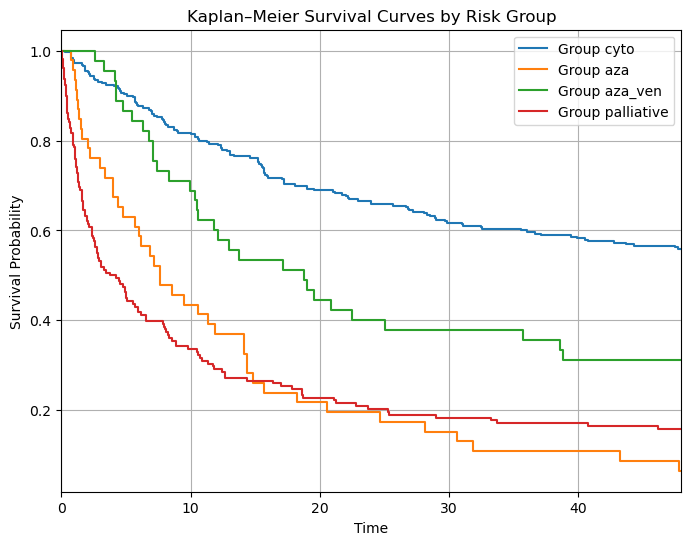

In [21]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

df = df_survival_bm.copy()
max_time = df["time_dg_to_death"].max()

df["time_dg_to_death"] = (
    df["time_dg_to_death"]
    .fillna(max_time)
    .dt.days / 30
)

print(max_time)
kmf = KaplanMeierFitter()

plt.figure(figsize=(8, 6))

for group in ["cyto", "aza", "aza_ven", "palliative"]:
    mask = df[group]  # rows belonging to the group
    
    kmf.fit(
        durations=df.loc[mask, "time_dg_to_death"],
        event_observed=df.loc[mask, "died"],
        label=f"Group {group}"
    )
    
    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Survival Curves by Risk Group")
plt.xlabel("Time")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.xlim((0, 48))


### 9) VAF data

In [22]:
df = pd.read_excel(AML_VAF_DATA_PATH)

df_vaf = df[["album_id", "year", "henkilotunnus", "Gene", "VAF"]]
df_vaf = df_vaf.rename(columns={"year": "database_id"})
df_vaf = df_vaf.dropna(subset="album_id")
df_vaf.album_id = df_vaf.album_id.astype(int)

# Pivot the DataFrame
df_vaf_new = df_vaf.pivot_table(
    index=['album_id', 'database_id', 'henkilotunnus'],  # Columns to keep as identifiers
    columns='Gene',                     # Column to pivot
    values='VAF'                        # Values to fill
).reset_index()

df_vaf_new.columns.name = None  # Remove the pivot table hierarchy

# get samples to match with VAF
sample_ids_bm = df_export_bm[["album_id", "database_id"]]
sample_ids_pb = df_export_pb[["album_id", "database_id"]]

sample_ids_bm["album_id"] = sample_ids_bm.album_id.astype(int)
sample_ids_pb["album_id"] = sample_ids_pb.album_id.astype(int)

vaf_data_bm = pd.merge(df_vaf_new, sample_ids_bm, on=["album_id", "database_id"], how="inner")
vaf_data_pb = pd.merge(df_vaf_new, sample_ids_pb, on=["album_id", "database_id"], how="inner")

# NOTE: mutation column names might not all match with the exported labelset because we have modified some labels for export
if SAVE_FILES:
    V = DATA_VERSION_IDENTIFIER
    save_with_dummy(vaf_data_bm, f"data/{V}/vaf/aml_mut_pred_vaf_values_bm_{V}.xlsx", id_columns=["album_id", "database_id", "henkilotunnus"])
    save_with_dummy(vaf_data_pb, f"data/{V}/vaf/aml_mut_pred_vaf_values_pb_{V}.xlsx", id_columns=["album_id", "database_id", "henkilotunnus"])

Saved: data/03-06-2026/vaf/aml_mut_pred_vaf_values_bm_03-06-2026.xlsx
Saved: data/03-06-2026/vaf/aml_mut_pred_vaf_values_bm_03-06-2026_DUMMY.xlsx
Saved: data/03-06-2026/vaf/aml_mut_pred_vaf_values_pb_03-06-2026.xlsx
Saved: data/03-06-2026/vaf/aml_mut_pred_vaf_values_pb_03-06-2026_DUMMY.xlsx
